In [1]:

import pandas as pd

data = {
    "Study_Hours": [2, 3, 1, 5, 4, 6, 2, 7, 3, 8,
                    5, 4, 9, 6, 1, 7, 3, 8, 5, 10],
    "Attendance": [60, 70, 55, 85, 80, 90, 65, 95, 72, 98,
                   88, 78, 96, 92, 50, 94, 68, 97, 86, 99],
    "Previous_Marks": [45, 55, 40, 65, 60, 75, 50, 80, 58, 85,
                       70, 62, 88, 78, 35, 82, 52, 90, 72, 95],
    "Final_Marks": [42, 52, 38, 68, 59, 78, 46, 83, 56, 89,
                    72, 60, 91, 80, 33, 85, 50, 93, 74, 97]
}

df = pd.DataFrame(data)

print(df.head())


   Study_Hours  Attendance  Previous_Marks  Final_Marks
0            2          60              45           42
1            3          70              55           52
2            1          55              40           38
3            5          85              65           68
4            4          80              60           59


In [2]:

print("Dataset information:")
print(df.info())

print("\nStatistical summary:")
print(df.describe())

print("\nMissing values:")
print(df.isnull().sum())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Study_Hours     20 non-null     int64
 1   Attendance      20 non-null     int64
 2   Previous_Marks  20 non-null     int64
 3   Final_Marks     20 non-null     int64
dtypes: int64(4)
memory usage: 772.0 bytes
None

Statistical summary:
       Study_Hours  Attendance  Previous_Marks  Final_Marks
count    20.000000   20.000000       20.000000    20.000000
mean      4.950000   80.900000       66.850000    67.300000
std       2.645254   15.331083       17.388063    19.722015
min       1.000000   50.000000       35.000000    33.000000
25%       3.000000   69.500000       54.250000    51.500000
50%       5.000000   85.500000       67.500000    70.000000
75%       7.000000   94.250000       80.500000    83.500000
max      10.000000   99.000000       95.000000    97.000000

Missing 

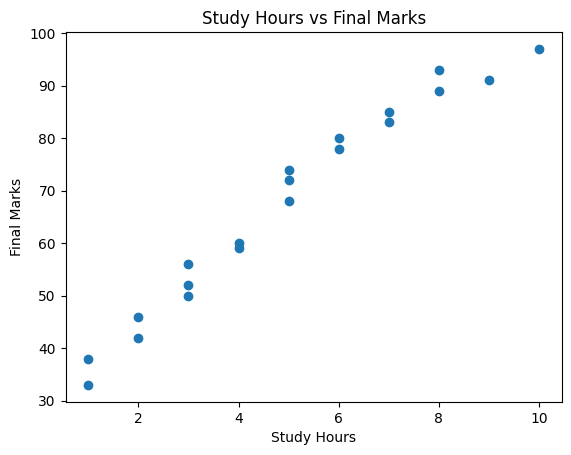

In [3]:

import matplotlib.pyplot as plt

plt.scatter(df["Study_Hours"], df["Final_Marks"])
plt.xlabel("Study Hours")
plt.ylabel("Final Marks")
plt.title("Study Hours vs Final Marks")
plt.show()


In [4]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Select input features
X = df[["Study_Hours", "Attendance", "Previous_Marks"]]

# Select the value to predict
y = df["Final_Marks"]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

# Create and train the model
model = LinearRegression()
model.fit(X_train, y_train)

print("Model training completed!")


Model training completed!


In [5]:

from sklearn.metrics import mean_absolute_error, r2_score

predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("Actual marks:", list(y_test))
print("Predicted marks:", predictions.round(2))
print("Mean Absolute Error:", round(mae, 2))
print("R-squared score:", round(r2, 2))


Actual marks: [42, 93, 85, 52, 56]
Predicted marks: [42.72 91.78 84.06 53.76 56.52]
Mean Absolute Error: 1.03
R-squared score: 1.0


In [6]:

new_student = pd.DataFrame({
    "Study_Hours": [6],
    "Attendance": [85],
    "Previous_Marks": [70]
})

predicted_marks = model.predict(new_student)[0]

print("Estimated Final Marks:", round(predicted_marks, 2))


Estimated Final Marks: 71.78


Model coefficients:
Study_Hours       0.974335
Previous_Marks    0.745912
Attendance        0.260866
dtype: float64


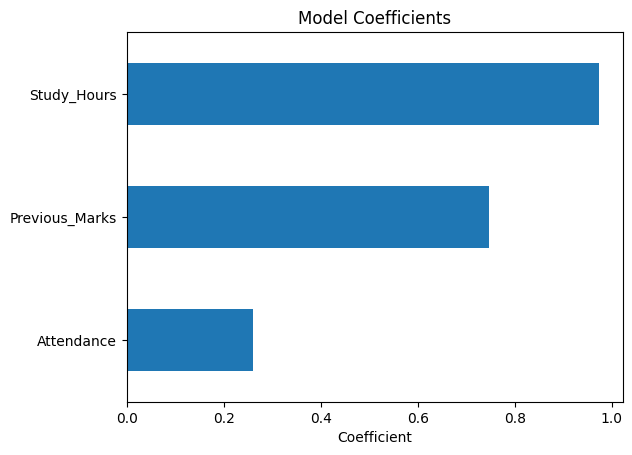

In [7]:

importance = pd.Series(
    model.coef_,
    index=X.columns
)

print("Model coefficients:")
print(importance.sort_values(ascending=False))

importance.sort_values().plot(kind="barh")
plt.title("Model Coefficients")
plt.xlabel("Coefficient")
plt.show()
